# Job 51194118 — the budget arm, and what a seed spread is made of

Stages A–F all ran 50 epochs (375k gradient steps at a 240k-instance pool), and
twelve of twenty-four multi-seed rungs were written off in those stages with the
words *"0 of 3 seeds escaped finding 44's 1.64 plateau, which is not evidence in
either direction"*. That caveat is honest and it is unfalsifiable until someone
spends the steps.

**Stage G (`51194118`, 6/6)** spends them. One knob moves — epochs 50 → 100 —
on the cheapest rung in the grid (**G1**, attention-only `d128`) and on the rung
that was the standing minimum when the job was written (**G2**, attention-only
`d256`), three seeds each, everything else identical. G2 is a PAIRED CONTROL
inside the same job, because nothing measured at 50 epochs is comparable across
a budget change.

**Two results, and the second one was not what the job was for.**

1. The 0.76 band is **not** a budget artifact. G2's median `rho_50` moved 0.763
   → 0.762 with every seed now past the plateau, against a registered threshold
   of 0.615 that would have forced a rereading of stages A–F.
2. G2's **seed spread collapsed from 0.2671 to 0.0041** in `mean_solve`. The
   seed that looked unlucky at 50 epochs — censored, best solve 0.465 — is at
   `rho_50` 0.761 and best solve 0.963 at 100, indistinguishable from its two
   siblings. The dispersion was one untrained seed, not three different answers.

Everything below is scored by `scripts/stageg_score.py`, committed (`dc7c08e`)
while tasks 0–1 were the only ones running and no stage G cell had finished.
This notebook runs it; it does not restate its conclusions in its own words.
Section 6 gives `rho_50` before and after on the same eval.

In [1]:
import json, os, subprocess, sys
sys.path.insert(0, "/home/users/hshunt/spin_gnn")
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

REPO = "/home/users/hshunt/spin_gnn"
BOOT = 2000          # the programme's scoring default; CIs here match the scorers'
SEEDS = (0, 1, 2)    # every rung here is 3 seeds

from scripts.minarch_analysis import SCAN_DIRS, SCAN_E, SCAN_G
from scripts.stagec_score import HUB, PLATEAU, S_RHO50, S_MEAN, escapes, rho_txt, rung, summarize
from scripts.stageg_score import (EPOCHS_G, FREE, G1, G1_TWIN, G2, G2_TWIN, G2_ARTIFACT,
                                  HEADER_ESCAPES, LOO_BAR, PRED_ESCAPES, TOL_CKPT,
                                  TWIN, TWIN_RUNG)
from notebooks.make_stageg_deck import E2, FULL_L12, collect, curve, gate, rescue

# SCAN_G is read here and HAS to be -- it is the subject. It stays out of
# SCAN_DIRS, and so out of every other notebook, because its rungs are the same
# architectures at a different budget and would pool into the s* that stages A-F
# were already scored against. s* is quoted frozen below and never recomputed.
DIRS = SCAN_DIRS + [SCAN_E, SCAN_G]

COMMIT = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=REPO,
                        capture_output=True, text=True).stdout.strip()
print("git commit        ", COMMIT)
print("branch            ", subprocess.run(["git", "rev-parse", "--abbrev-ref", "HEAD"],
                                           cwd=REPO, capture_output=True,
                                           text=True).stdout.strip())
print("bootstrap draws   ", BOOT)
print("frozen yardstick  ", f"s* = {S_RHO50} in rho_50, {S_MEAN} in mean_solve")
print("plateau           ", f"train NLL {PLATEAU} (finding 44)")
print("thresholds        ", f"free at rho_50 <= {FREE}; the 0.76 band is a budget artifact "
                            f"if G2 < {G2_ARTIFACT};")
print("                  ", f"epoch-50 reproduction tolerance {TOL_CKPT} nats")
print("scan dirs         ", len(DIRS), "dirs, subject is", os.path.basename(SCAN_G))

git commit         dd9c400
branch             sudoku-dd
bootstrap draws    2000
frozen yardstick   s* = 0.1484 in rho_50, 0.2918 in mean_solve
plateau            train NLL 1.64 (finding 44)
thresholds         free at rho_50 <= 0.74; the 0.76 band is a budget artifact if G2 < 0.615;
                   epoch-50 reproduction tolerance 0.01 nats
scan dirs          6 dirs, subject is sudoku_n48_minarch_G_2026-11-05


## 1. Provenance: one knob, asserted rather than assumed

Read off each cell's `config.json` rather than from the sbatch header. The
100-epoch cells must differ from their 50-epoch twins in `epochs` and in nothing
else — not in `lr`, not in `batch_size`, not in the pool size, not in the seed.
A difference anywhere else and the pairing is void.

In [2]:
cells, rows = collect(DIRS, BOOT)
g1, g2 = summarize(rung(cells, G1)), summarize(rung(cells, G2))
t1, t2 = summarize(rung(cells, G1_TWIN)), summarize(rung(cells, G2_TWIN))
print(f"{len(cells)} cells on disk | G1 {g1['n']}/3 seeds, G2 {g2['n']}/3 seeds\n")

FIELDS = ("epochs", "num_layers", "d_model", "dim_feedforward", "nhead", "arch_mode",
          "lr", "batch_size", "n_train_instances", "warmup_epochs", "shuffle_adj", "fall",
          "n_nodes", "degree", "n_colors")
print(f"{'cell':<22}" + "".join(f"{f.replace('_', ' ')[:9]:>11}" for f in FIELDS[:6]))
print("-" * 88)
for nm, key in (("G1  d128, 50 ep", G1_TWIN), ("G1  d128, 100 ep", G1),
                ("G2  d256, 50 ep", G2_TWIN), ("G2  d256, 100 ep", G2)):
    cfg = json.load(open(os.path.join(rung(cells, key)[0]["path"], "config.json")))
    print(f"{nm:<22}" + "".join(f"{str(cfg.get(f)):>11}" for f in FIELDS[:6]))

print()
for tag, key, twin_key in (("G1", G1, G1_TWIN), ("G2", G2, G2_TWIN)):
    for m, t in zip(rung(cells, key), rung(cells, twin_key)):
        a = json.load(open(os.path.join(m["path"], "config.json")))
        b = json.load(open(os.path.join(t["path"], "config.json")))
        # solve_metrics is the eval RESULT, written back into config.json by the
        # runner; out_dir/run_name carry the task index. Neither is an input.
        diff = sorted(k for k in set(a) | set(b) if a.get(k) != b.get(k)
                      and k not in ("out_dir", "run_name", "epochs", "solve_metrics"))
        print(f"  {tag} seed {a['seed']}: fields differing from its twin besides epochs: "
              f"{diff or 'NONE'}")
print()
print("held constant across all six cells:",
      "  ".join(f"{f}={a.get(f)}" for f in FIELDS[6:]))

84 cells on disk | G1 3/3 seeds, G2 3/3 seeds

cell                       epochs  num layer    d model  dim feedf      nhead  arch mode
----------------------------------------------------------------------------------------
G1  d128, 50 ep                50          6        128       1024          4     no_mlp
G1  d128, 100 ep              100          6        128       1024          4     no_mlp
G2  d256, 50 ep                50          6        256       1024          4     no_mlp
G2  d256, 100 ep              100          6        256       1024          4     no_mlp

  G1 seed 0: fields differing from its twin besides epochs: NONE
  G1 seed 1: fields differing from its twin besides epochs: NONE
  G1 seed 2: fields differing from its twin besides epochs: NONE
  G2 seed 0: fields differing from its twin besides epochs: NONE
  G2 seed 1: fields differing from its twin besides epochs: NONE
  G2 seed 2: fields differing from its twin besides epochs: NONE

held constant across all si

## 2. The epoch-50 reproduction gate

With a constant learning rate, no warmup, a fixed pool and the same seed, the
first 50 epochs of a 100-epoch run **are** the 50-epoch run. That is checkable,
so it is checked: each 100-epoch cell's epoch-50 train NLL must match its twin's
final train NLL to within 0.01 nats, a tolerance registered in the scorer before
the job ran.

A cell that missed the gate would not be a twin of anything, and would be
reported inconclusive rather than explained.

In [3]:
print(f"{'cell':<12}{'epoch-50':>10}{'twin final':>13}{'delta':>9}   verdict")
print("-" * 52)
worst = 0.0
for tag, key, twin_key in (("G1", G1, G1_TWIN), ("G2", G2, G2_TWIN)):
    for seed, got, want, d, ok in gate(cells, key, twin_key):
        worst = max(worst, abs(d))
        print(f"{tag + ' seed ' + str(seed):<12}{got:>10.3f}{want:>13.3f}{d:>+9.3f}   "
              f"{'ok' if ok else 'MISMATCH'}")
print(f"\nworst |delta| {worst:.4f} against a tolerance of {TOL_CKPT} -- the pairing holds "
      f"for all 6 cells")

cell          epoch-50   twin final    delta   verdict
----------------------------------------------------
G1 seed 0        1.725        1.725   -0.000   ok
G1 seed 1        1.739        1.738   +0.001   ok
G1 seed 2        1.701        1.706   -0.006   ok
G2 seed 0        1.629        1.631   -0.002   ok
G2 seed 1        1.679        1.688   -0.010   ok
G2 seed 2        1.605        1.597   +0.008   ok

worst |delta| 0.0095 against a tolerance of 0.01 -- the pairing holds for all 6 cells


## 3. The metrics table

`rho_50` is the realized hint density at which the solve rate crosses 0.5 on a
14-point × 400-instance leak-free grid — **lower is better** — and it CENSORS
once no bin clears 0.5. `mean_solve` is the unweighted mean over the 14 bins and
never censors, which is why censored rungs are still readable here.

Read the `cross` and `spread` columns together with `rho_50`. The median is a
summary over three seeds; it moves only when the MIDDLE seed moves, so a rung
can gain an entire solving seed without its median shifting at all. That is
exactly what G2 does.

In [4]:
print(f"{'rung':<20}{'rho_50':>10}{'mean_solve':>12}{'spread':>9}"
      f"{'trainable':>12}{'esc':>6}{'cross':>7}   train NLL per seed")
print("-" * 116)
for nm, key in (("G1 d128,  50 ep", G1_TWIN), ("G1 d128, 100 ep", G1),
                ("G2 d256,  50 ep", G2_TWIN), ("G2 d256, 100 ep", G2)):
    ms = rung(cells, key)
    s, (n_esc, nll) = summarize(ms), escapes(ms)
    print(f"{nm:<20}{rho_txt(s):>10}{s['mean_solve']:>12.4f}{s['spread_mean']:>9.4f}"
          f"{s['trainable']:>12,}{n_esc:>4}/{s['n']}{s['n_cross']:>5}/{s['n']}   "
          + "/".join(f"{v:.3f}" for v in nll))

print("\nPER SEED, the row the median hides")
print(f"  {'cell':<14}{'rho_50':>10}{'mean_solve':>12}{'best solve':>12}"
      f"{'token acc':>11}{'train NLL':>11}")
print("  " + "-" * 70)
for tag, key, twin_key in (("G1", G1, G1_TWIN), ("G2", G2, G2_TWIN)):
    for ep, k in ((50, twin_key), (EPOCHS_G, key)):
        for j, m in enumerate(rung(cells, k)):
            r = f"{m['rho50']:.3f}" if m["flag"] == "ok" else "CENSORED"
            nll, acc = curve(m["path"])[0][-1], curve(m["path"])[1][-1]
            print(f"  {tag + ' s' + str(j) + ' ' + str(ep) + 'ep':<14}{r:>10}"
                  f"{m['mean_solve']:>12.4f}{m['best_solve']:>12.3f}{acc:>11.4f}{nll:>11.3f}")
    print()

r = rescue(cells)
if r:
    print(f"the one seed that changed category: {r['tag']} seed {r['seed']}")
    print(f"  censored, best solve {r['best_before']:.3f}, train NLL {r['nll_before']:.3f}, "
          f"token acc {r['acc_before']:.4f}   at 50 epochs")
    print(f"  rho_50 {r['rho_after']:.3f}, best solve {r['best_after']:.3f}, train NLL "
          f"{r['nll_after']:.3f}, token acc {r['acc_after']:.4f}   at {EPOCHS_G}")
    print(f"  mean_solve {r['mean_before']:.4f} -> {r['mean_after']:.4f}")

rung                    rho_50  mean_solve   spread   trainable   esc  cross   train NLL per seed
--------------------------------------------------------------------------------------------------------------------
G1 d128,  50 ep       CENSORED      0.0291   0.2075     480,058   0/3    1/3   1.725/1.738/1.706
G1 d128, 100 ep       CENSORED      0.0287   0.2168     480,058   0/3    1/3   1.711/1.727/1.687
G2 d256,  50 ep          0.763      0.3039   0.2671   1,746,490   2/3    2/3   1.631/1.688/1.597
G2 d256, 100 ep          0.762      0.3070   0.0041   1,746,490   3/3    3/3   1.620/1.631/1.592

PER SEED, the row the median hides
  cell              rho_50  mean_solve  best solve  token acc  train NLL
  ----------------------------------------------------------------------
  G1 s0 50ep      CENSORED      0.0284       0.318     0.4558      1.725
  G1 s1 50ep      CENSORED      0.0291       0.350     0.4540      1.738
  G1 s2 50ep         0.806      0.2359       0.915     0.4744      1.

## 4. The pre-registered scorer, run as it was committed

`scripts/stageg_score.py` transcribes the thresholds from stage G's sbatch
header, runs the epoch-50 integrity gate FIRST, and refuses to score a rung with
fewer than three seeds.

Three things in its output were registered to be reported *ahead* of any
verdict:

* **the asymmetry on G1** — G1 escaping the plateau would have proved the budget
  was binding at the cheap end; G1 *not* escaping proves nothing, and there is
  no symmetric reading available. The scorer enforces that, so the reader cannot
  quietly take the convenient half.
* **two contradictory predictions about G2** — the sbatch header (`4a35a2e`)
  said 3 of 3 seeds escape, `escape_timing.py`'s extrapolation (`dc7c08e`) said
  2 of 3. One of them is wrong in print, which is the point of writing both
  down.
* **G4**, the free out-of-sample sufficiency test: every rung not in stage G is
  held out and asked whether its solve rate sits on the curve mapping token
  accuracy to solving — now including three cells at a budget the curve was
  never fitted at.

In [5]:
out = subprocess.run([sys.executable, "-m", "scripts.stageg_score", "--boot", str(BOOT)],
                     cwd=REPO, capture_output=True, text=True)
print(out.stdout)
if out.returncode:
    print("STDERR:", out.stderr[-2000:])

STAGE G: is the cheap end excluded by CAPACITY, or by the BUDGET?
  78 cells read; ONE knob, epochs 50 -> 100, fixed 240k pool
  frozen bar s* = 0.1484 rho_50 / 0.2918 mean_solve, NOT recomputed
  G1's rho_50 against the 0.76 band is CROSS-BUDGET and is not scored.

FROZEN-LITERAL CONTROL (the 50-epoch twins, re-read from disk):
  G1 twin matches the frozen literals
  G2 twin matches the frozen literals

=== G2 -- THE PAIRED CONTROL, standing minimum no_mlp d256 at 100 epochs ===
  3/3 seeds on disk at 100 epochs, 3/3 crossed 0.5
  trainable 1,746,490   (50-epoch twin 1,746,490)
  THE ONLY LEGITIMATE WITHIN-RUNG COMPARISON, this cell vs its own twin:
    rho_50          0.762   twin     0.763
    mean_solve     0.3070   twin    0.3039   [spread 0.0041 / 0.2671]
    escapes        3/3        twin    2/3
    train NLL   1.620/1.631/1.592
  registered, sbatch header (4a35a2e): escapes 3
  registered, extrapolation (this file): escapes 2 of 3
  per-seed extrapolation, predicted as a LOWER 

## 5. The figures

The same figures as pages 4 and 5 of the slide deck, drawn by the deck's own
code so the two cannot drift apart.

In the first, dashed is the 50-epoch twin and solid the 100-epoch run; they lie
on top of each other until epoch 50 by construction, and section 2 asserts it.
In the second, each line is one seed on the identical eval grid — one line
moves, and it moves onto the other two.

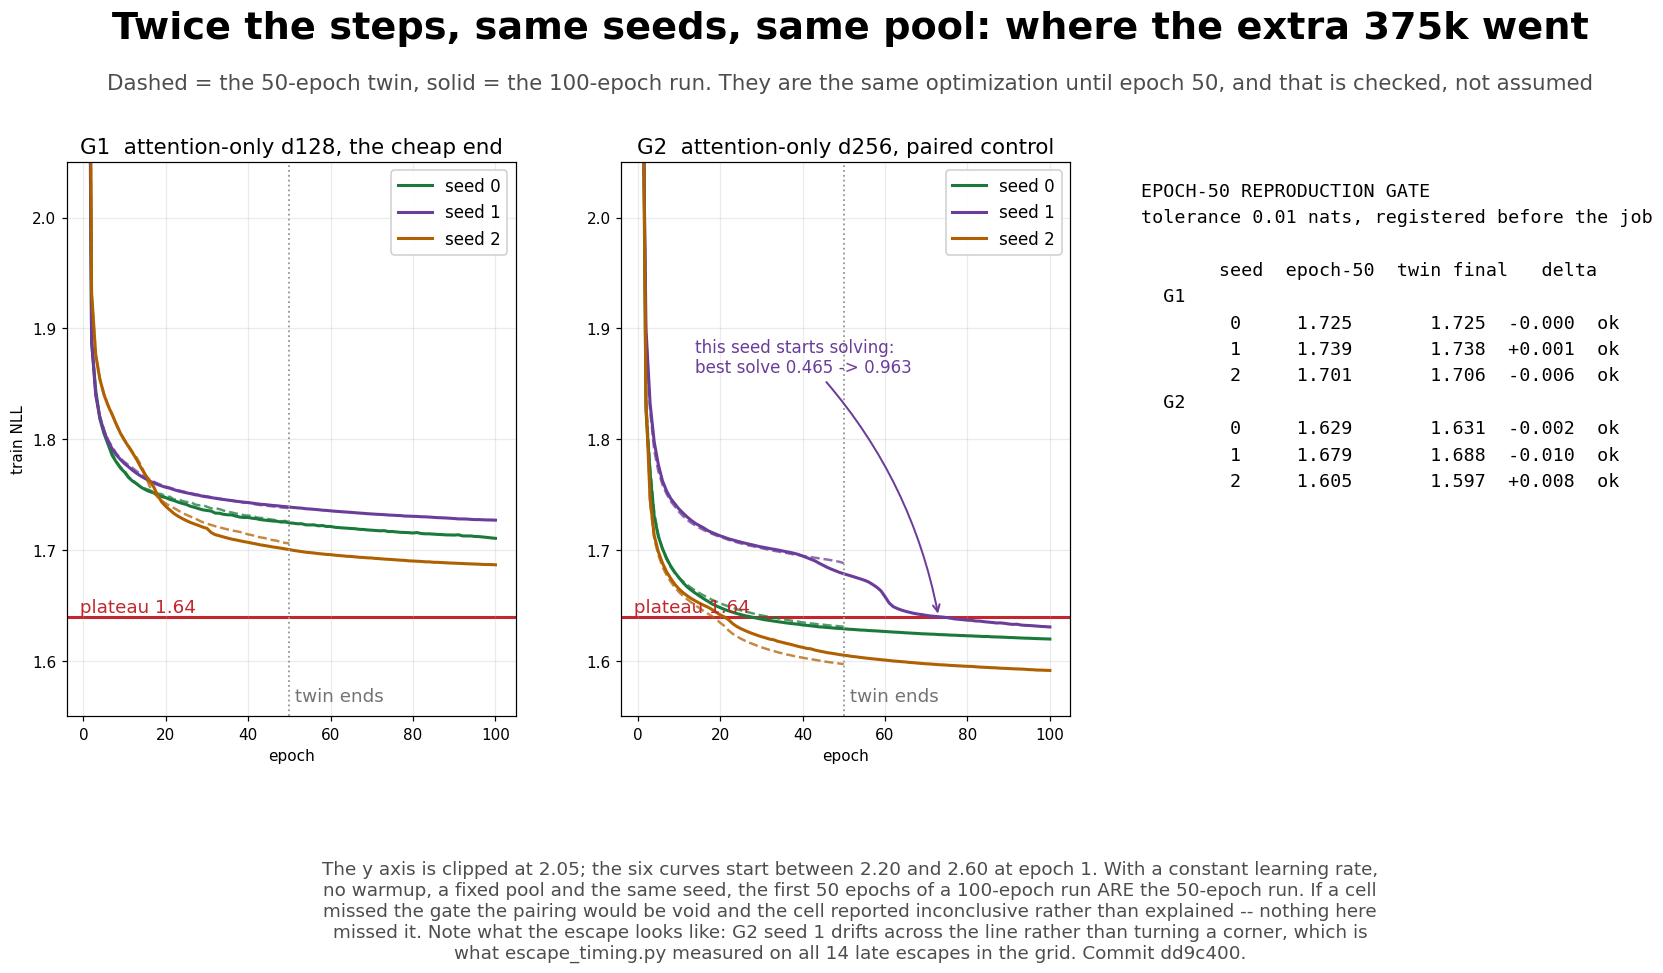

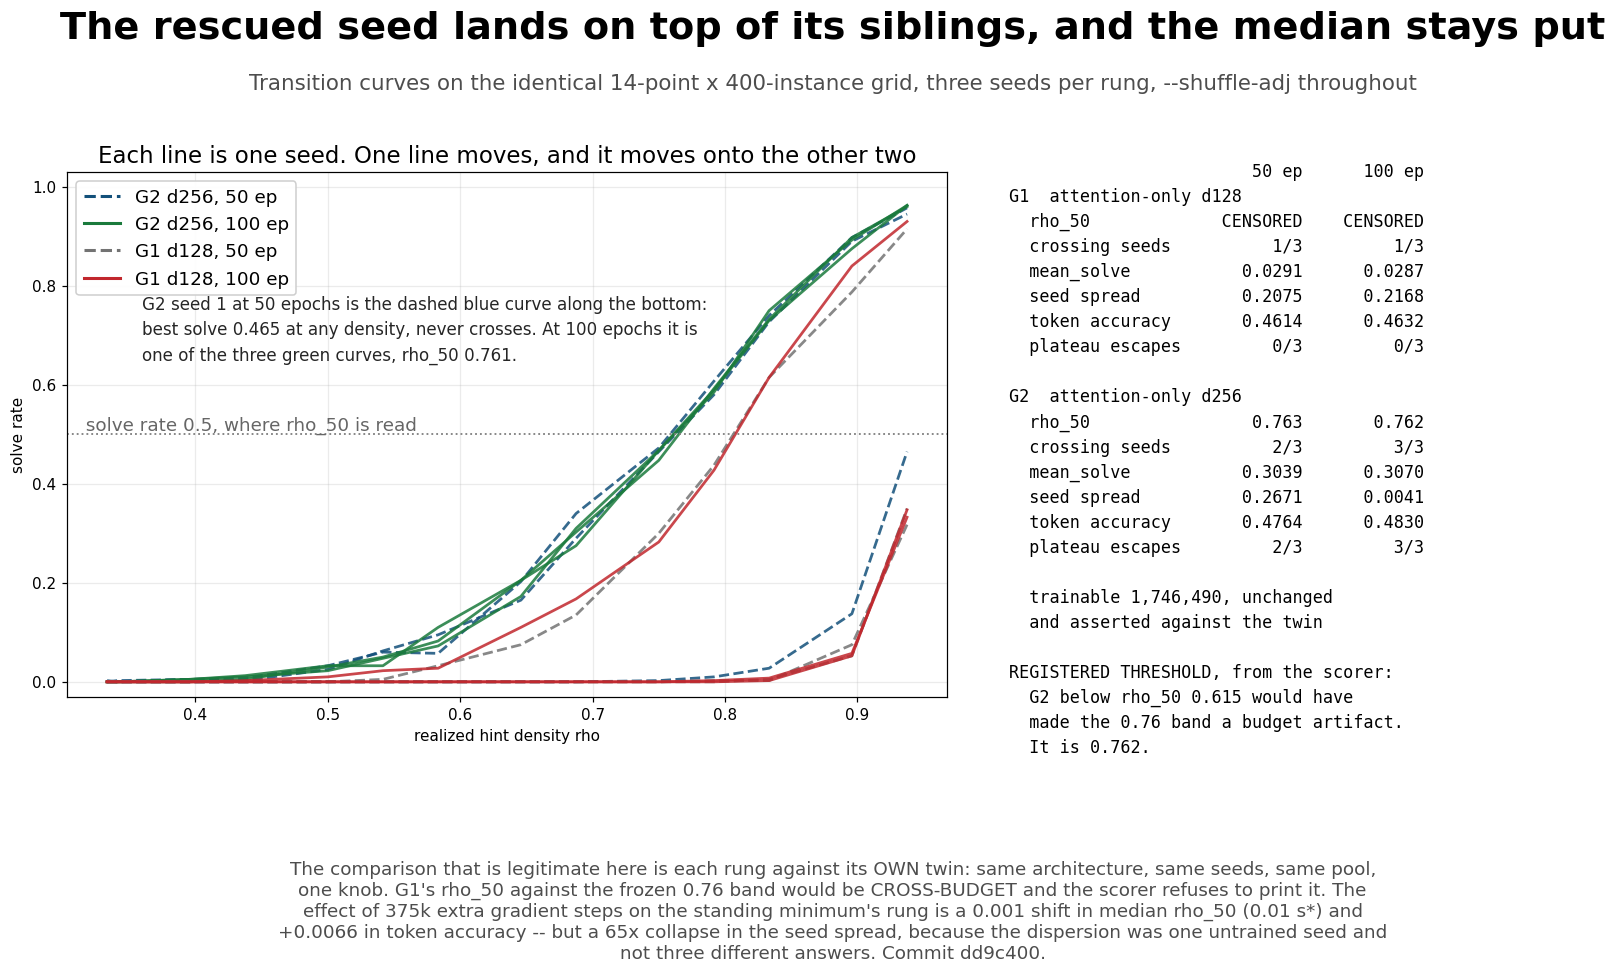

In [6]:
from notebooks.make_stageg_deck import page_bought, page_training


class Keep:
    """A PdfAndPng stand-in that keeps the figure open for the notebook."""

    def savefig(self, fig):
        pass


page_training(Keep(), cells, COMMIT)
page_bought(Keep(), cells, rows, g1, g2, t1, t2, COMMIT)

## 6. `rho_50` before and after, on the same eval

The eval is unchanged — the same 14-point × 400-instance leak-free grid,
`--shuffle-adj --fall` throughout, and the same frozen seed-spread bar `s*` =
0.1484 / 0.2918, fixed before any of these cells ran and not recomputed here.

Two comparisons are legitimate and they answer different questions:

* **each rung against its OWN twin** (same architecture, same seeds, same pool,
  one knob) — what the extra 375k steps bought;
* **G2 against the standing minimum and the hub**, which are 50-epoch rungs, so
  this one is CROSS-BUDGET and is reported as context, not as a verdict.

No improvement is claimed. The budget arm was run to find out whether an earlier
negative result was an artifact; it was not, and that is the result.

In [7]:
print("EACH RUNG AGAINST ITS OWN TWIN -- same architecture, same seeds, one knob")
print(f"  {'rung':<22}{'rho_50':>10}{'mean_solve':>12}{'spread':>9}{'cross':>8}{'esc':>6}")
print("  " + "-" * 67)
for nm, key in (("BEFORE  G2 d256 50 ep", G2_TWIN), ("AFTER   G2 d256 100 ep", G2),
                ("BEFORE  G1 d128 50 ep", G1_TWIN), ("AFTER   G1 d128 100 ep", G1)):
    ms = rung(cells, key)
    s, (n_esc, _) = summarize(ms), escapes(ms)
    print(f"  {nm:<22}{rho_txt(s):>10}{s['mean_solve']:>12.4f}{s['spread_mean']:>9.4f}"
          f"{s['n_cross']:>5}/{s['n']}{n_esc:>4}/{s['n']}")
d = abs(g2["rho50"] - t2["rho50"])
print()
print(f"  G2 median rho_50 moved {d:.3f} ({d / S_RHO50:.2f} s*), against the registered "
      f"{G2_ARTIFACT} that would")
print(f"  have made the 0.76 band a budget artifact. It did not come close, so the band stands.")
print(f"  Crossing seeds {TWIN_RUNG['G2'][1]}/3 -> {g2['n_cross']}/3 and seed spread "
      f"{TWIN_RUNG['G2'][4]:.4f} -> {g2['spread_mean']:.4f} "
      f"({TWIN_RUNG['G2'][4] / max(g2['spread_mean'], 1e-9):.0f}x).")
print(f"  G1 is unchanged where it counts: censored, {g1['n_cross']}/3 crossing, "
      f"{escapes(rung(cells, G1))[0]}/3 escaping.")
print(f"  By the registered asymmetry that is 'did not train',")
print(f"  not 'cannot represent it', and no capacity claim follows from it.")

e2, hub = summarize(rung(cells, E2)), summarize(rung(cells, HUB))
l12 = summarize(rung(cells, FULL_L12))
print()
print("CONTEXT, CROSS-BUDGET -- these three are 50-epoch rungs and are NOT twins of G2")
print(f"  {'rung':<30}{'rho_50':>10}{'mean_solve':>12}{'trainable':>12}")
print("  " + "-" * 64)
for nm, s in (("standing minimum  no_mlp L=12", e2), ("hub               full L=6", hub),
              ("best solver       full L=12", l12), ("G2 at 100 ep      no_mlp L=6", g2)):
    print(f"  {nm:<30}{rho_txt(s):>10}{s['mean_solve']:>12.4f}{s['trainable']:>12,}")
print()
print(f"  G3 -- the rule that would have moved the standing minimum (3 of 3 crossing AND "
      f"median <= {FREE})")
print(f"  did not fire: G2 crosses on {g2['n_cross']} of 3 but at {rho_txt(g2)}, above "
      f"{FREE}. The standing minimum is")
print(f"  unchanged at {rho_txt(e2)} on {e2['trainable']:,} trainable.")

EACH RUNG AGAINST ITS OWN TWIN -- same architecture, same seeds, one knob
  rung                      rho_50  mean_solve   spread   cross   esc
  -------------------------------------------------------------------
  BEFORE  G2 d256 50 ep      0.763      0.3039   0.2671    2/3   2/3
  AFTER   G2 d256 100 ep     0.762      0.3070   0.0041    3/3   3/3
  BEFORE  G1 d128 50 ep   CENSORED      0.0291   0.2075    1/3   0/3
  AFTER   G1 d128 100 ep  CENSORED      0.0287   0.2168    1/3   0/3

  G2 median rho_50 moved 0.001 (0.01 s*), against the registered 0.615 that would
  have made the 0.76 band a budget artifact. It did not come close, so the band stands.
  Crossing seeds 2/3 -> 3/3 and seed spread 0.2671 -> 0.0041 (65x).
  G1 is unchanged where it counts: censored, 1/3 crossing, 0/3 escaping.
  By the registered asymmetry that is 'did not train',
  not 'cannot represent it', and no capacity claim follows from it.

CONTEXT, CROSS-BUDGET -- these three are 50-epoch rungs and are NOT twins 

## 7. What this does not settle, and what is still running

**Whether `d128` can ever learn this is still open, on purpose.** G1 is censored
at 0 of 3 escapes after 750k steps. The registered reading is "did not train",
not "cannot represent it", and the next cell on that question is 200 epochs
rather than a conclusion — one this programme has not committed to, because the
extrapolation that would justify it is the one this job just showed to be an
upper bound.

**The extrapolation result is the part that generalizes.** `escape_timing.py`'s
Q3 fitted each stalled cell's last-20% slope and projected an ETA for its escape.
G2 seed 1 crossed a gap its own terminal slope put 72 epochs away, and it is the
one cell of six to land below its extrapolated bound. The tails bend down rather
than running straight, so Q3's ETAs are UPPER bounds and its count of 10 cells
recoverable within another 50 epochs is an undercount.

**The seed-spread result is the part that changes how earlier rungs are read.**
`s*` was pooled at 50 epochs, so it is inflated by seeds that had not finished
training: a conservative bar, not a tight one. A 2-of-3 rung at 50 epochs should
be read as "one seed is not finished" rather than "this architecture is
unreliable". This does not invalidate any verdict scored against `s*` — a wider
bar makes a claimed separation harder, not easier — but it means the programme
has been paying for an excuse it may not need.

**`51223007` stage H** is in flight: attention-only at `L=12`, `d128` and
`d192`, three seeds each, asking whether the depth that bought the MLP back
survives being made narrow. Its scorer (`scripts/stageh_score.py`, `a4a6405`)
was registered and dry-run clean before its first cell landed, as this one was.

**Stage F**, a 3-seed replicate at N=96, stays unwritten until stage H is
scored, because what it replicates depends on which rung is standing then.